In [1]:
import os, pickle, random, math, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pad_sequence

from torchvision import models, transforms
from PIL import Image
from tqdm import tqdm

import nltk
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score as nltk_meteor

TPU_AVAILABLE = False
try:
    import torch_xla
    import torch_xla.core.xla_model as xm
    device = xm.xla_device()
    TPU_AVAILABLE = True
    print(f"✅ Using TPU device: {device}")
except ImportError:
    if torch.cuda.is_available():
        device = torch.device("cuda")
        print(f"✅ Using GPU: {torch.cuda.get_device_name(0)}")
        print(f"   GPUs available: {torch.cuda.device_count()}")
    else:
        device = torch.device("cpu")
        print("⚠️  Using CPU (no TPU or GPU detected)")

# ----- reproducibility -----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

✅ Using GPU: Tesla T4
   GPUs available: 2


In [2]:
def find_image_dir():
    base_input = '/kaggle/input'
    for root, dirs, files in os.walk(base_input):
        jpg_count = len([f for f in files if f.lower().endswith(('.jpg', '.jpeg'))])
        if jpg_count > 1000:
            return root
    return None

IMAGE_DIR = find_image_dir()
OUTPUT_FILE = 'flickr30k_features.pkl'

if IMAGE_DIR:
    print(f"Found images at: {IMAGE_DIR}")
    all_jpg = [f for f in os.listdir(IMAGE_DIR) if f.lower().endswith(('.jpg', '.jpeg'))]
    print(f"   Total images: {len(all_jpg)}")
else:
    raise FileNotFoundError(
        "Could not find the Flickr30k image directory. "
        "Please ensure the dataset is added to the notebook."
    )

class FlickrImageDataset(Dataset):

    def __init__(self, img_dir, transform):
        self.img_names = sorted([f for f in os.listdir(img_dir)
                                 if f.lower().endswith(('.jpg', '.jpeg'))])
        self.transform = transform
        self.img_dir = img_dir

    def __len__(self):
        return len(self.img_names)

    def __getitem__(self, idx):
        name = self.img_names[idx]
        img = Image.open(os.path.join(self.img_dir, name)).convert('RGB')
        return self.transform(img), name

# ---------- transforms ----------
img_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406),
                         (0.229, 0.224, 0.225))
])

# ---------- model ----------
resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
resnet = nn.Sequential(*list(resnet.children())[:-1])   # remove classifier → 2048-D
resnet = resnet.to(device)
resnet.eval()

# ---------- extract ----------
dataset_img = FlickrImageDataset(IMAGE_DIR, img_transform)
loader_img  = DataLoader(dataset_img, batch_size=64, num_workers=2, drop_last=False)
features_dict = {}

with torch.no_grad():
    for imgs, names in tqdm(loader_img, desc="🔄 Extracting Features"):
        feats = resnet(imgs.to(device)).view(imgs.size(0), -1)   # (B, 2048)
        for i, name in enumerate(names):
            features_dict[name] = feats[i].cpu().numpy()

# ---------- save ----------
with open(OUTPUT_FILE, 'wb') as f:
    pickle.dump(features_dict, f)

print(f"Success! {len(features_dict)} images → {OUTPUT_FILE}")

Found images at: /kaggle/input/datasets/adityajn105/flickr30k/Images
   Total images: 31783
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 223MB/s] 
🔄 Extracting Features: 100%|██████████| 497/497 [40:06<00:00,  4.84s/it]


Success! 31783 images → flickr30k_features.pkl


In [4]:
def find_captions_file():
    """Locate captions.txt (or results.csv) inside /kaggle/input."""
    for root, dirs, files in os.walk('/kaggle/input'):
        for f in files:
            if f.lower() in ('captions.txt', 'results.csv', 'captions.csv'):
                return os.path.join(root, f)
    return None

caption_path = find_captions_file()
if caption_path is None:
    raise FileNotFoundError("Could not find captions file in /kaggle/input")
print(f"Captions file: {caption_path}")

Captions file: /kaggle/input/datasets/adityajn105/flickr30k/captions.txt


In [5]:
# Try multiple separators and pick whichever gives us proper columns
df_raw = None
for sep_char in [',', '|', '\t']:
    try:
        _df = pd.read_csv(caption_path, sep=sep_char, on_bad_lines='skip')
        if len(_df.columns) >= 2:
            df_raw = _df
            print(f"Parsed with separator: {repr(sep_char)}")
            break
    except Exception:
        continue

# If all separators gave a single column, split manually on first comma
if df_raw is None or len(df_raw.columns) < 2:
    print("   ⚠️  Standard parsing failed. Splitting lines on first comma...")
    lines = open(caption_path, 'r', encoding='utf-8').readlines()
    data_rows = []
    for line in lines[1:]:                       # skip header
        line = line.strip()
        if not line:
            continue
        parts = line.split(',', 1)               # split on FIRST comma only
        if len(parts) == 2:
            data_rows.append({'image': parts[0].strip(), 'caption': parts[1].strip()})
    df_raw = pd.DataFrame(data_rows)

df_raw.columns = [c.strip().lower() for c in df_raw.columns]
print(f"📊 Raw shape: {df_raw.shape}")
print(f"   Columns: {df_raw.columns.tolist()}")
print(df_raw.head())

# --- Robust column detection ---
image_candidates = ['image', 'image_name', 'filename', 'img', 'img_name', 'file']
image_col = next((c for c in image_candidates if c in df_raw.columns), df_raw.columns[0])

caption_candidates = ['caption', 'comment', 'captions', 'text', 'description', 'sentence']
caption_col = next((c for c in caption_candidates if c in df_raw.columns), df_raw.columns[-1])

print(f"Image column: '{image_col}' | Caption column: '{caption_col}'")

# Rename to standard names
if image_col != 'image' or caption_col != 'caption':
    df_raw = df_raw.rename(columns={image_col: 'image', caption_col: 'caption'})

# Keep only the two columns we need and drop bad rows
df_raw = df_raw[['image', 'caption']].dropna().reset_index(drop=True)

df_raw['caption'] = df_raw['caption'].astype(str).str.strip()
df_raw['image']   = df_raw['image'].astype(str).str.strip()

Parsed with separator: ','
📊 Raw shape: (158915, 2)
   Columns: ['image', 'caption']
            image                                            caption
0  1000092795.jpg   Two young guys with shaggy hair look at their...
1  1000092795.jpg   Two young , White males are outside near many...
2  1000092795.jpg   Two men in green shirts are standing in a yard .
3  1000092795.jpg       A man in a blue shirt standing in a garden .
4  1000092795.jpg            Two friends enjoy time spent together .
Image column: 'image' | Caption column: 'caption'


In [6]:
print("=" * 70)
print("📝 10 RAW CAPTIONS (as loaded from the file)")
print("=" * 70)
for i in range(min(10, len(df_raw))):
    print(f"  [{i+1}] Image: {df_raw.iloc[i]['image']}")
    print(f"       Caption: {df_raw.iloc[i]['caption']}")
    print("-" * 60)

📝 10 RAW CAPTIONS (as loaded from the file)
  [1] Image: 1000092795.jpg
       Caption: Two young guys with shaggy hair look at their hands while hanging out in the yard .
------------------------------------------------------------
  [2] Image: 1000092795.jpg
       Caption: Two young , White males are outside near many bushes .
------------------------------------------------------------
  [3] Image: 1000092795.jpg
       Caption: Two men in green shirts are standing in a yard .
------------------------------------------------------------
  [4] Image: 1000092795.jpg
       Caption: A man in a blue shirt standing in a garden .
------------------------------------------------------------
  [5] Image: 1000092795.jpg
       Caption: Two friends enjoy time spent together .
------------------------------------------------------------
  [6] Image: 10002456.jpg
       Caption: Several men in hard hats are operating a giant pulley system .
-----------------------------------------------------

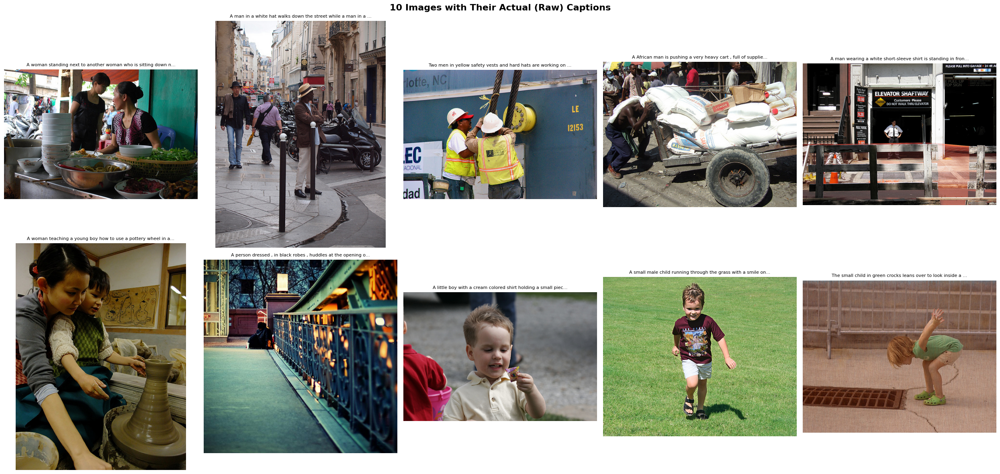

10 images with raw captions displayed!


In [7]:
# Pick 10 unique images that exist in the image directory
# Re-find IMAGE_DIR if cell 1 was skipped
if 'IMAGE_DIR' not in dir() or IMAGE_DIR is None:
    for root, dirs, files in os.walk('/kaggle/input'):
        if len([f for f in files if f.lower().endswith('.jpg')]) > 1000:
            IMAGE_DIR = root
            break
    print(f"Re-detected IMAGE_DIR: {IMAGE_DIR}")
available_images = set(f for f in os.listdir(IMAGE_DIR) if f.lower().endswith(('.jpg', '.jpeg')))
imgs_with_caps = df_raw[df_raw['image'].isin(available_images)]['image'].unique()
sample_10 = random.sample(list(imgs_with_caps), min(10, len(imgs_with_caps)))

fig, axes = plt.subplots(2, 5, figsize=(25, 12))
fig.suptitle("10 Images with Their Actual (Raw) Captions", fontsize=16, fontweight='bold')

for ax, img_name in zip(axes.flatten(), sample_10):
    img_path = os.path.join(IMAGE_DIR, img_name)
    img = Image.open(img_path).convert('RGB')
    ax.imshow(img)
    ax.axis('off')

    # Get first raw caption for this image
    raw_cap = df_raw[df_raw['image'] == img_name]['caption'].iloc[0]
    # Wrap long captions
    wrapped = raw_cap[:60] + "..." if len(raw_cap) > 60 else raw_cap
    ax.set_title(wrapped, fontsize=8, wrap=True)

plt.tight_layout()
plt.show()
print("10 images with raw captions displayed!")

In [8]:
# ----- cleaning function -----
def clean_caption(text):
    """Lowercase, remove special chars, collapse whitespace."""
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_raw['caption_clean'] = df_raw['caption'].apply(clean_caption)

# Keep only images that we have features for
df = df_raw[df_raw['image'].isin(available_images)].reset_index(drop=True)
print(f"Captions matched with features: {len(df)}")

Captions matched with features: 158914


In [9]:
print("=" * 80)
print("CAPTIONS: BEFORE PROCESSING vs AFTER PROCESSING")
print("=" * 80)

for i in range(min(10, len(df))):
    raw  = df.iloc[i]['caption']
    clean = df.iloc[i]['caption_clean']
    print(f"\n  Sample {i+1} | Image: {df.iloc[i]['image']}")
    print(f"  BEFORE (raw):      \"{raw}\"")
    print(f"  AFTER  (cleaned):  \"{clean}\"")
    print("-" * 70)

CAPTIONS: BEFORE PROCESSING vs AFTER PROCESSING

  Sample 1 | Image: 1000092795.jpg
  BEFORE (raw):      "Two young guys with shaggy hair look at their hands while hanging out in the yard ."
  AFTER  (cleaned):  "two young guys with shaggy hair look at their hands while hanging out in the yard"
----------------------------------------------------------------------

  Sample 2 | Image: 1000092795.jpg
  BEFORE (raw):      "Two young , White males are outside near many bushes ."
  AFTER  (cleaned):  "two young white males are outside near many bushes"
----------------------------------------------------------------------

  Sample 3 | Image: 1000092795.jpg
  BEFORE (raw):      "Two men in green shirts are standing in a yard ."
  AFTER  (cleaned):  "two men in green shirts are standing in a yard"
----------------------------------------------------------------------

  Sample 4 | Image: 1000092795.jpg
  BEFORE (raw):      "A man in a blue shirt standing in a garden ."
  AFTER  (cleaned):  

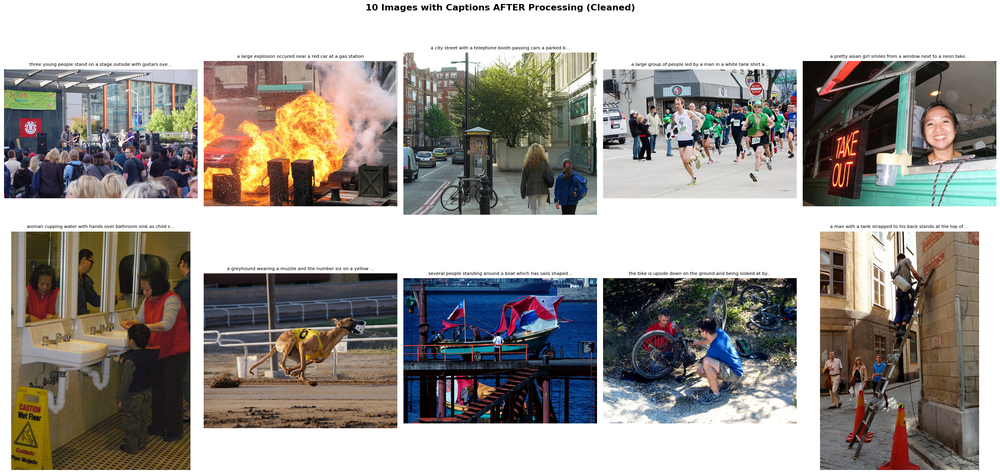

10 images with processed captions displayed!


In [10]:
sample_proc = random.sample(list(df['image'].unique()), min(10, len(df['image'].unique())))

fig, axes = plt.subplots(2, 5, figsize=(25, 12))
fig.suptitle("10 Images with Captions AFTER Processing (Cleaned)", fontsize=16, fontweight='bold')

for ax, img_name in zip(axes.flatten(), sample_proc):
    img_path = os.path.join(IMAGE_DIR, img_name)
    img = Image.open(img_path).convert('RGB')
    ax.imshow(img)
    ax.axis('off')

    clean_cap = df[df['image'] == img_name]['caption_clean'].iloc[0]
    wrapped = clean_cap[:60] + "..." if len(clean_cap) > 60 else clean_cap
    ax.set_title(wrapped, fontsize=8, wrap=True)

plt.tight_layout()
plt.show()
print("10 images with processed captions displayed!")


In [11]:
# Special tokens
PAD_TOKEN   = '<pad>'
START_TOKEN = '<start>'
END_TOKEN   = '<end>'
UNK_TOKEN   = '<unk>'

MIN_WORD_FREQ = 3   # words appearing fewer times → <unk>

# Count word frequencies across ALL captions
word_counts = Counter()
for cap in df['caption_clean']:
    word_counts.update(cap.split())

print(f"Total unique words (before filtering): {len(word_counts)}")

# Build vocab: special tokens + frequent words
vocab_list = [PAD_TOKEN, START_TOKEN, END_TOKEN, UNK_TOKEN]
vocab_list += [w for w, c in word_counts.items() if c >= MIN_WORD_FREQ]

word2idx = {w: i for i, w in enumerate(vocab_list)}
idx2word = {i: w for w, i in word2idx.items()}

VOCAB_SIZE = len(vocab_list)
PAD_IDX   = word2idx[PAD_TOKEN]
START_IDX = word2idx[START_TOKEN]
END_IDX   = word2idx[END_TOKEN]
UNK_IDX   = word2idx[UNK_TOKEN]

print(f"✅ Vocabulary size (freq ≥ {MIN_WORD_FREQ}): {VOCAB_SIZE}")
print(f"   PAD={PAD_IDX}, START={START_IDX}, END={END_IDX}, UNK={UNK_IDX}")

# ----- Encode a caption string to list of indices -----
def encode_caption(text):
    """Convert clean caption → [START, w1, w2, ..., END] index list."""
    tokens = text.split()
    indices = [START_IDX] + [word2idx.get(w, UNK_IDX) for w in tokens] + [END_IDX]
    return indices

# Quick sanity check
sample_cap = df['caption_clean'].iloc[0]
encoded = encode_caption(sample_cap)
decoded = ' '.join(idx2word[i] for i in encoded)
print(f"\n🔍 Sample caption : {sample_cap}")
print(f"   Encoded        : {encoded[:15]}...")
print(f"   Decoded back   : {decoded[:80]}...")

Total unique words (before filtering): 20007
✅ Vocabulary size (freq ≥ 3): 10029
   PAD=0, START=1, END=2, UNK=3

🔍 Sample caption : two young guys with shaggy hair look at their hands while hanging out in the yard
   Encoded        : [1, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]...
   Decoded back   : <start> two young guys with shaggy hair look at their hands while hanging out in...


In [12]:
# Encoder: Image Feature → Hidden State
EMBED_SIZE  = 512    # Dimension for word embeddings
HIDDEN_SIZE = 1024    # LSTM hidden size
NUM_LAYERS  = 1      # Number of LSTM layers
DROPOUT     = 0.5    # Dropout probability

class Encoder(nn.Module):
    """
    Encoder: takes a 2048-D ResNet feature vector and projects it
    into the hidden dimension used by the Decoder LSTM.
    """
    def __init__(self, feature_dim=2048, hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.fc   = nn.Linear(feature_dim, hidden_size)
        self.bn   = nn.BatchNorm1d(hidden_size)
        self.relu = nn.ReLU()

    def forward(self, features):
        """
        Args:   features: (batch, 2048) image feature vectors
        Returns: projected: (batch, hidden_size)
        """
        projected = self.relu(self.bn(self.fc(features)))   # (B, hidden_size)
        return projected

In [13]:
# ============================================================
# CELL 6 — Decoder: LSTM-based Caption Generator
# ============================================================

class Decoder(nn.Module):
    """
    Decoder LSTM:
      - Embedding layer converts word indices to dense vectors.
      - LSTM consumes embeddings step-by-step.
      - Initial hidden state comes from the Encoder output.
      - Linear layer maps LSTM output → vocabulary logits.
    """
    def __init__(self, vocab_size, embed_size=EMBED_SIZE,
                 hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.embed   = nn.Embedding(vocab_size, embed_size, padding_idx=PAD_IDX)
        self.lstm    = nn.LSTM(embed_size, hidden_size, num_layers,
                               batch_first=True,
                               dropout=dropout if num_layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.fc      = nn.Linear(hidden_size, vocab_size)

    def forward(self, captions, hidden, cell):
        """
        Teacher-forcing forward pass.
        Args:
            captions : (B, seq_len)  word indices
            hidden   : (num_layers, B, hidden_size)
            cell     : (num_layers, B, hidden_size)
        Returns:
            outputs  : (B, seq_len, vocab_size) logits
        """
        embeddings = self.dropout(self.embed(captions))           # (B, seq, embed)
        lstm_out, (hidden, cell) = self.lstm(embeddings, (hidden, cell))
        outputs = self.fc(lstm_out)                                # (B, seq, V)
        return outputs, hidden, cell


In [14]:
#  Seq2Seq wrapper model
class Seq2SeqCaptioner(nn.Module):
    """Combines Encoder + Decoder into a single captioning model."""
    def __init__(self, encoder, decoder, hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS):
        super().__init__()
        self.encoder     = encoder
        self.decoder     = decoder
        self.num_layers  = num_layers
        self.hidden_size = hidden_size

    def forward(self, features, captions):
        """
        Args:
            features : (B, 2048) cached image features
            captions : (B, seq_len) target captions (with <start>, without last token)
        Returns:
            outputs  : (B, seq_len, vocab_size) logits
        """
        enc_out = self.encoder(features)                           # (B, hidden_size)
        hidden  = enc_out.unsqueeze(0).repeat(self.num_layers, 1, 1)
        cell    = torch.zeros_like(hidden)
        outputs, _, _ = self.decoder(captions, hidden, cell)
        return outputs

encoder_model = Encoder(feature_dim=2048, hidden_size=HIDDEN_SIZE)
decoder_model = Decoder(VOCAB_SIZE, EMBED_SIZE, HIDDEN_SIZE, NUM_LAYERS, DROPOUT)
model = Seq2SeqCaptioner(encoder_model, decoder_model, HIDDEN_SIZE, NUM_LAYERS).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable    = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Seq2Seq model created on {device}")
print(f"Total params     : {total_params:,}")
print(f"Trainable params : {trainable:,}")


Seq2Seq model created on cuda
Total params     : 23,814,445
Trainable params : 23,814,445


In [15]:
#Training dataset & dataloader
class CaptionDataset(Dataset):
    """
    PyTorch Dataset that returns (image_features, encoded_caption) pairs.
    Each image has ~5 captions; we treat each caption as a separate sample.
    """
    def __init__(self, dataframe, features_dict):
        self.data = dataframe.reset_index(drop=True)
        self.features_dict = features_dict

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row  = self.data.iloc[idx]
        feat = torch.tensor(self.features_dict[row['image']], dtype=torch.float32)
        cap  = torch.tensor(encode_caption(row['caption_clean']), dtype=torch.long)
        return feat, cap

def collate_fn(batch):
    """Pad captions to equal length within a batch."""
    features, captions = zip(*batch)
    features = torch.stack(features, dim=0)                          # (B, 2048)
    captions = pad_sequence(captions, batch_first=True,
                            padding_value=PAD_IDX)                   # (B, max_len)
    return features, captions


all_images = df['image'].unique().tolist()
random.shuffle(all_images)
split_idx  = int(0.9 * len(all_images))
train_imgs = set(all_images[:split_idx])
val_imgs   = set(all_images[split_idx:])

df_train = df[df['image'].isin(train_imgs)].reset_index(drop=True)
df_val   = df[df['image'].isin(val_imgs)].reset_index(drop=True)

print(f"Train images: {len(train_imgs)},  captions: {len(df_train)}")
print(f"Val   images: {len(val_imgs)},    captions: {len(df_val)}")

BATCH_SIZE = 128
train_dataset = CaptionDataset(df_train, features_dict)
val_dataset   = CaptionDataset(df_val,   features_dict)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True, collate_fn=collate_fn,
                          num_workers=2, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
                          shuffle=False, collate_fn=collate_fn,
                          num_workers=2, drop_last=False)


Train images: 28604,  captions: 143019
Val   images: 3179,    captions: 15895


In [ ]:
NUM_EPOCHS    = 30
LEARNING_RATE = 3e-4
CLIP_GRAD     = 5.0     # gradient clipping to prevent exploding gradients

# Loss: CrossEntropyLoss ignoring PAD tokens
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min',
                                                  factor=0.5, patience=3)

train_losses = []
val_losses   = []
train_accs   = []
val_accs     = []

print(f"🚀 Training for {NUM_EPOCHS} epochs | LR={LEARNING_RATE} | Batch={BATCH_SIZE}")
print(f"   Device: {device} | TPU: {TPU_AVAILABLE}")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS + 1):

    model.train()
    epoch_loss = 0.0
    epoch_acc  = 0.0

    for features, captions in tqdm(train_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [train]"):
        features = features.to(device)           # (B, 2048)
        captions = captions.to(device)           # (B, seq_len)

        cap_input  = captions[:, :-1]
        cap_target = captions[:, 1:]

        outputs = model(features, cap_input)     # (B, seq_len-1, vocab_size)

        # Reshape for cross-entropy: (B*(seq_len-1), V) vs (B*(seq_len-1))
        loss = criterion(outputs.reshape(-1, VOCAB_SIZE), cap_target.reshape(-1))

        optimizer.zero_grad() 
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CLIP_GRAD)

        # TPU-aware optimizer step
        if TPU_AVAILABLE:
            xm.optimizer_step(optimizer)
            xm.mark_step()
        else:
            optimizer.step()

        preds = outputs.argmax(dim=2).reshape(-1)
        targets = cap_target.reshape(-1)
        mask = targets != PAD_IDX
        acc = (preds[mask] == targets[mask]).float().mean()

        epoch_loss += loss.item()
        epoch_acc += acc.item()

    avg_train_loss = epoch_loss / len(train_loader)
    avg_train_acc  = epoch_acc  / len(train_loader)
    train_losses.append(avg_train_loss)
    train_accs.append(avg_train_acc)

    # ---------- VALIDATE ----------
    model.eval()
    epoch_val_loss = 0.0
    epoch_val_acc  = 0.0

    with torch.no_grad():
        for features, captions in tqdm(val_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [val]"):
            features = features.to(device)
            captions = captions.to(device)

            cap_input  = captions[:, :-1]
            cap_target = captions[:, 1:]

            outputs = model(features, cap_input)
            loss = criterion(outputs.reshape(-1, VOCAB_SIZE), cap_target.reshape(-1))
            epoch_val_loss += loss.item()

            preds = outputs.argmax(dim=2).reshape(-1)
            targets = cap_target.reshape(-1)
            mask = targets != PAD_IDX
            acc = (preds[mask] == targets[mask]).float().mean()
            epoch_val_acc += acc.item()

    avg_val_loss = epoch_val_loss / max(len(val_loader), 1)
    avg_val_acc  = epoch_val_acc  / max(len(val_loader), 1)
    val_losses.append(avg_val_loss)
    val_accs.append(avg_val_acc)

    scheduler.step(avg_val_loss)

    print(f"  Epoch {epoch:02d} — Train Loss: {avg_train_loss:.4f} (Acc: {avg_train_acc:.4f}) |  Val Loss: {avg_val_loss:.4f} (Acc: {avg_val_acc:.4f})")

print("\n Training complete!")


🚀 Training for 30 epochs | LR=0.0003 | Batch=128
   Device: cuda | TPU: False


Epoch 1/30 [val]: 100%|██████████| 125/125 [00:07<00:00, 16.43it/s]


  Epoch 01 — Train Loss: 3.9922 (Acc: 0.3081) |  Val Loss: 3.3860 (Acc: 0.3588)


Epoch 2/30 [val]: 100%|██████████| 125/125 [00:07<00:00, 16.23it/s]


  Epoch 02 — Train Loss: 3.2277 (Acc: 0.3706) |  Val Loss: 3.1435 (Acc: 0.3823)


...

Epoch 28/30 [val]: 100%|██████████| 125/125 [00:07<00:00, 16.29it/s]


  Epoch 28 — Train Loss: 1.7729 (Acc: 0.5573) |  Val Loss: 3.1526 (Acc: 0.3920)


Epoch 29/30 [val]: 100%|██████████| 125/125 [00:07<00:00, 16.32it/s]


  Epoch 29 — Train Loss: 1.7704 (Acc: 0.5580) |  Val Loss: 3.1553 (Acc: 0.3923)


Epoch 30/30 [train]:  84%|████████▍ | 943/1117 [02:32<00:30,  5.69it/s]

In [28]:
#  Greedy search & Beam search
MAX_CAP_LEN = 40   # maximum words to generate

@torch.no_grad()
def greedy_search(model, feature_vec, max_len=MAX_CAP_LEN):
    """
    Greedy decoding: at each step pick the word with the highest probability.
    Args:
        model       : trained Seq2SeqCaptioner
        feature_vec : (2048,) numpy array — single image feature
    Returns:
        caption (str)
    """
    model.eval()
    feat = torch.tensor(feature_vec, dtype=torch.float32).unsqueeze(0).to(device)  # (1,2048)

    enc_out = model.encoder(feat)                              # (1, hidden_size)
    hidden  = enc_out.unsqueeze(0).repeat(model.num_layers, 1, 1)
    cell    = torch.zeros_like(hidden)

    input_tok = torch.tensor([[START_IDX]], device=device)      # (1, 1)
    words = []

    for _ in range(max_len):
        output, hidden, cell = model.decoder(input_tok, hidden, cell)  # (1,1,vocab)
        predicted = output.argmax(dim=2)                                # (1,1)
        word_idx  = predicted.item()

        if word_idx == END_IDX:
            break
        words.append(idx2word.get(word_idx, UNK_TOKEN))
        input_tok = predicted

    return ' '.join(words)

@torch.no_grad()
def beam_search(model, feature_vec, beam_width=5, max_len=MAX_CAP_LEN):
    """
    Beam search decoding: maintain top-k hypotheses at each step.
    """
    model.eval()
    feat = torch.tensor(feature_vec, dtype=torch.float32).unsqueeze(0).to(device)

    enc_out = model.encoder(feat)
    hidden  = enc_out.unsqueeze(0).repeat(model.num_layers, 1, 1)
    cell    = torch.zeros_like(hidden)

    # Each beam: (log_prob, [word_indices], hidden, cell)
    beams     = [(0.0, [START_IDX], hidden, cell)]
    completed = []

    for _ in range(max_len):
        candidates = []
        for log_prob, seq, h, c in beams:
            last_tok = torch.tensor([[seq[-1]]], device=device)
            output, h_new, c_new = model.decoder(last_tok, h, c)
            log_probs = torch.log_softmax(output.squeeze(0).squeeze(0), dim=0)
            topk_probs, topk_idx = log_probs.topk(beam_width)

            for k in range(beam_width):
                w = topk_idx[k].item()
                new_seq = seq + [w]
                new_log = log_prob + topk_probs[k].item()
                if w == END_IDX:
                    completed.append((new_log, new_seq))
                else:
                    candidates.append((new_log, new_seq, h_new, c_new))

        if not candidates:
            break
        candidates.sort(key=lambda x: x[0], reverse=True)
        beams = [(lp, s, h, c) for lp, s, h, c in candidates[:beam_width]]

    if not completed:
        completed = [(lp, s) for lp, s, _, _ in beams]

    completed.sort(key=lambda x: x[0] / max(len(x[1]), 1), reverse=True)
    best_seq = completed[0][1]
    words = [idx2word.get(i, UNK_TOKEN) for i in best_seq
             if i not in (START_IDX, END_IDX, PAD_IDX)]
    return ' '.join(words)

# Quick test on a random validation image
test_img  = df_val['image'].iloc[0]
test_feat = features_dict[test_img]
print(f"Image: {test_img}")
print(f"Greedy : {greedy_search(model, test_feat)}")
print(f"Beam-5 : {beam_search(model, test_feat, beam_width=5)}")

Image: 1001896054.jpg
Greedy : man in blue shirt and blue shorts driving a tractor
Beam-5 : a man in a blue shirt is sitting on a tractor


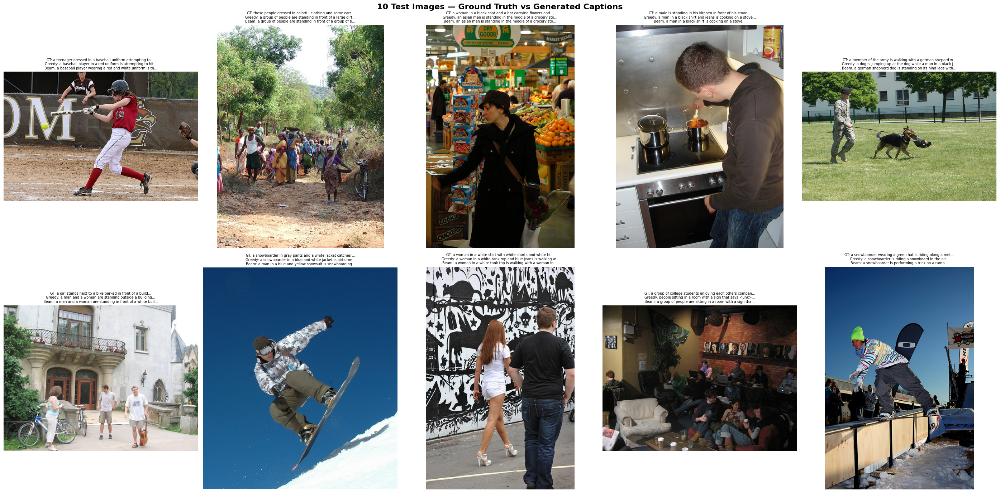


GENERATED CAPTIONS FOR 10 TEST IMAGES

  [1] Image: 3516299821.jpg
      Ground Truth : a teenager dressed in a baseball uniform attempting to hit a baseball during a game
      Greedy Gen.  : a baseball player in a red uniform is attempting to hit a ball
      Beam-5 Gen.  : a baseball player wearing a red and white uniform is throwing a baseball
----------------------------------------------------------------------

  [2] Image: 3972670198.jpg
      Ground Truth : these people dressed in colorful clothing and some carrying baskets are walking up the dry stream bed on their pilgrimage back home from the market
      Greedy Gen.  : a group of people are standing in front of a large dirt bike
      Beam-5 Gen.  : a group of people are standing in front of a group of bicycles
----------------------------------------------------------------------

  [3] Image: 327762135.jpg
      Ground Truth : a woman in a black coat and a hat carrying flowers and other purchases around a market
      G

In [29]:
# For 10 random validation images, display the image, ground-truth
# caption, and the model's generated caption (Greedy + Beam).

sample_test_imgs = random.sample(df_val['image'].unique().tolist(),
                                  min(10, len(df_val['image'].unique())))

fig, axes = plt.subplots(2, 5, figsize=(28, 14))
fig.suptitle("10 Test Images — Ground Truth vs Generated Captions",
             fontsize=16, fontweight='bold')

for ax, img_name in zip(axes.flatten(), sample_test_imgs):
    # Display image
    img_path = os.path.join(IMAGE_DIR, img_name)
    img = Image.open(img_path).convert('RGB')
    ax.imshow(img)
    ax.axis('off')

    # Ground truth
    gt_caps = df_val[df_val['image'] == img_name]['caption_clean'].tolist()
    gt_text = gt_caps[0] if gt_caps else 'N/A'

    # Model predictions
    feat       = features_dict[img_name]
    greedy_cap = greedy_search(model, feat)
    beam_cap   = beam_search(model, feat, beam_width=5)

    title = (f"GT: {gt_text[:55]}...\n"
             f"Greedy: {greedy_cap[:55]}...\n"
             f"Beam: {beam_cap[:55]}...")
    ax.set_title(title, fontsize=7, wrap=True, ha='center')

plt.tight_layout()
plt.savefig('test_captions_10.png', dpi=150, bbox_inches='tight')
plt.show()

# Also print them clearly in text form
print("\n" + "=" * 80)
print("GENERATED CAPTIONS FOR 10 TEST IMAGES")
print("=" * 80)
for i, img_name in enumerate(sample_test_imgs):
    gt_caps = df_val[df_val['image'] == img_name]['caption_clean'].tolist()
    feat    = features_dict[img_name]
    greedy_cap = greedy_search(model, feat)
    beam_cap   = beam_search(model, feat, beam_width=5)

    print(f"\n  [{i+1}] Image: {img_name}")
    print(f"      Ground Truth : {gt_caps[0] if gt_caps else 'N/A'}")
    print(f"      Greedy Gen.  : {greedy_cap}")
    print(f"      Beam-5 Gen.  : {beam_cap}")
    print("-" * 70)

print("10 test images with generated captions displayed!")


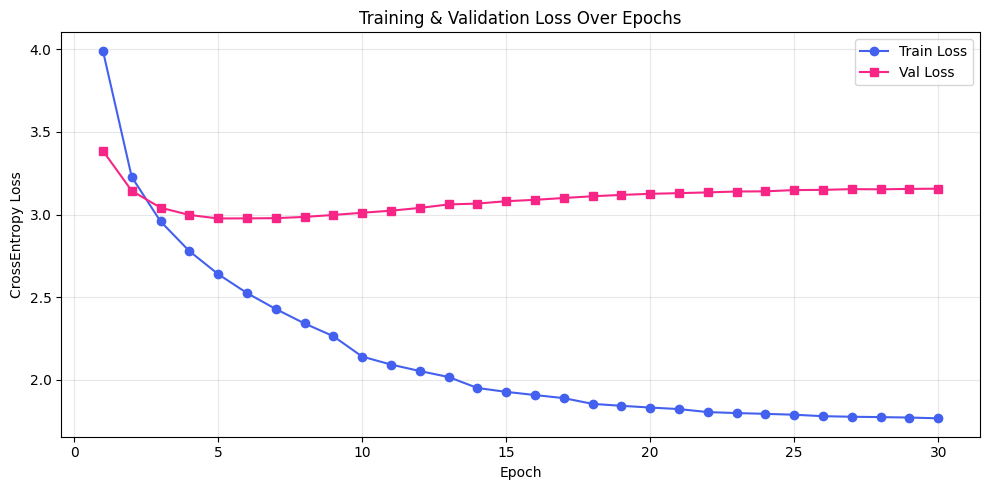

Loss curve saved to loss_curve.png


In [30]:
# training and validation loss

plt.figure(figsize=(10, 5))
epochs_range = range(1, NUM_EPOCHS + 1)
plt.plot(epochs_range, train_losses, 'o-', label='Train Loss', color='#4361ee')
plt.plot(epochs_range, val_losses,   's-', label='Val Loss',   color='#f72585')
plt.xlabel('Epoch')
plt.ylabel('CrossEntropy Loss')
plt.title('Training & Validation Loss Over Epochs')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('loss_curve.png', dpi=150)
plt.show()
print("Loss curve saved to loss_curve.png")


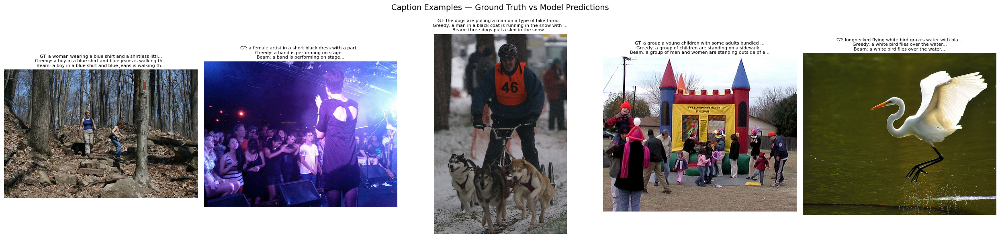

✅ Caption examples saved to caption_examples.png


In [31]:
# ============================================================
# CELL 12 — Display 5 random test images with captions
# ============================================================

sample_val_images = random.sample(df_val['image'].unique().tolist(),
                                   min(5, len(df_val['image'].unique())))

fig, axes = plt.subplots(1, 5, figsize=(25, 6))

for ax, img_name in zip(axes, sample_val_images):
    img_path = os.path.join(IMAGE_DIR, img_name)
    img = Image.open(img_path).convert('RGB')
    ax.imshow(img)
    ax.axis('off')

    gt_caps = df_val[df_val['image'] == img_name]['caption_clean'].tolist()
    gt_text = gt_caps[0] if gt_caps else 'N/A'

    feat       = features_dict[img_name]
    greedy_cap = greedy_search(model, feat)
    beam_cap   = beam_search(model, feat, beam_width=5)

    ax.set_title(
        f"GT: {gt_text[:50]}...\n"
        f"Greedy: {greedy_cap[:50]}...\n"
        f"Beam: {beam_cap[:50]}...",
        fontsize=8, wrap=True
    )

plt.suptitle('Caption Examples — Ground Truth vs Model Predictions', fontsize=14)
plt.tight_layout()
plt.savefig('caption_examples.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Caption examples saved to caption_examples.png")


In [32]:
# ============================================================
# CELL 13 — Evaluate on full validation set
# ============================================================

print("🔄 Evaluating on validation set...")

# Group ground-truth captions by image
gt_by_image = defaultdict(list)
for _, row in df_val.iterrows():
    gt_by_image[row['image']].append(row['caption_clean'].split())

# Generate predictions for each val image
references       = []
hypotheses_greedy = []
hypotheses_beam   = []

val_image_list = list(gt_by_image.keys())
for img_name in tqdm(val_image_list, desc="Generating captions"):
    feat = features_dict[img_name]

    greedy_cap    = greedy_search(model, feat)
    greedy_tokens = greedy_cap.split()
    hypotheses_greedy.append(greedy_tokens)

    beam_cap    = beam_search(model, feat, beam_width=5)
    beam_tokens = beam_cap.split()
    hypotheses_beam.append(beam_tokens)

    references.append(gt_by_image[img_name])

print(f"✅ Generated captions for {len(val_image_list)} validation images")


🔄 Evaluating on validation set...


Generating captions: 100%|██████████| 3179/3179 [07:40<00:00,  6.90it/s]

✅ Generated captions for 3179 validation images


In [33]:
# ============================================================
# CELL 14 — BLEU-4 Score
# ============================================================

smooth = SmoothingFunction().method1

bleu4_greedy = corpus_bleu(references, hypotheses_greedy, smoothing_function=smooth)
bleu4_beam   = corpus_bleu(references, hypotheses_beam,   smoothing_function=smooth)

print(f" BLEU-4 (Greedy) : {bleu4_greedy:.4f}")
print(f" BLEU-4 (Beam-5) : {bleu4_beam:.4f}")

 BLEU-4 (Greedy) : 0.1714
 BLEU-4 (Beam-5) : 0.1810


In [34]:
# ============================================================
# CELL 15 — Precision, Recall, F1 (token-level)
# ============================================================

def token_level_metrics(references_list, hypotheses_list):
    """
    Compute token-level Precision, Recall, F1 averaged over all samples.
    """
    total_p, total_r, total_f1 = 0.0, 0.0, 0.0
    n = len(hypotheses_list)

    for refs, hyp in zip(references_list, hypotheses_list):
        ref_tokens = set()
        for r in refs:
            ref_tokens.update(r)
        hyp_tokens = set(hyp)

        if len(hyp_tokens) == 0 and len(ref_tokens) == 0:
            total_p += 1.0; total_r += 1.0; total_f1 += 1.0
            continue

        common    = hyp_tokens & ref_tokens
        precision = len(common) / len(hyp_tokens) if hyp_tokens else 0
        recall    = len(common) / len(ref_tokens) if ref_tokens else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0

        total_p  += precision
        total_r  += recall
        total_f1 += f1

    return total_p / n, total_r / n, total_f1 / n

p_g, r_g, f1_g = token_level_metrics(references, hypotheses_greedy)
p_b, r_b, f1_b = token_level_metrics(references, hypotheses_beam)

print(f"\n Token-Level Metrics (Greedy):")
print(f"   Precision : {p_g:.4f}")
print(f"   Recall    : {r_g:.4f}")
print(f"   F1-Score  : {f1_g:.4f}")

print(f"\n Token-Level Metrics (Beam-5):")
print(f"   Precision : {p_b:.4f}")
print(f"   Recall    : {r_b:.4f}")
print(f"   F1-Score  : {f1_b:.4f}")


 Token-Level Metrics (Greedy):
   Precision : 0.5842
   Recall    : 0.1833
   F1-Score  : 0.2729

 Token-Level Metrics (Beam-5):
   Precision : 0.5898
   Recall    : 0.1928
   F1-Score  : 0.2845


In [35]:
# ============================================================
# CELL 16 — METEOR Score
# ============================================================

meteor_scores_greedy = []
meteor_scores_beam   = []

for refs, hyp_g, hyp_b in zip(references, hypotheses_greedy, hypotheses_beam):
    # NLTK meteor_score expects tokenized lists, not strings
    meteor_scores_greedy.append(nltk_meteor(refs, hyp_g))
    meteor_scores_beam.append(nltk_meteor(refs, hyp_b))

avg_meteor_greedy = np.mean(meteor_scores_greedy)
avg_meteor_beam   = np.mean(meteor_scores_beam)

print(f" METEOR (Greedy) : {avg_meteor_greedy:.4f}")
print(f" METEOR (Beam-5) : {avg_meteor_beam:.4f}")


 METEOR (Greedy) : 0.3677
 METEOR (Beam-5) : 0.3827


In [36]:
# ============================================================
# CELL 17 — Summary table of all metrics
# ============================================================

metrics_data = {
    'Metric':  ['BLEU-4', 'Precision', 'Recall', 'F1-Score', 'METEOR'],
    'Greedy':  [f"{bleu4_greedy:.4f}", f"{p_g:.4f}", f"{r_g:.4f}", f"{f1_g:.4f}", f"{avg_meteor_greedy:.4f}"],
    'Beam-5':  [f"{bleu4_beam:.4f}",   f"{p_b:.4f}", f"{r_b:.4f}", f"{f1_b:.4f}", f"{avg_meteor_beam:.4f}"],
}
metrics_df = pd.DataFrame(metrics_data)
print("\n" + "=" * 50)
print("         EVALUATION SUMMARY")
print("=" * 50)
print(metrics_df.to_string(index=False))
print("=" * 50)


         EVALUATION SUMMARY
   Metric Greedy Beam-5
   BLEU-4 0.1714 0.1810
Precision 0.5842 0.5898
   Recall 0.1833 0.1928
 F1-Score 0.2729 0.2845
   METEOR 0.3677 0.3827


In [37]:
# ============================================================
# SAVE CHECKPOINT FOR STREAMLIT APP
# ============================================================
import torch

torch.save({
    'model_state_dict': model.state_dict(),
    'vocab': {
        'word2idx': word2idx, 
        'idx2word': idx2word, 
        'min_freq': MIN_WORD_FREQ
    },
    'config': {
        'vocab_size': VOCAB_SIZE, 
        'embed_size': EMBED_SIZE, 
        'hidden_size': HIDDEN_SIZE, 
        'num_layers': NUM_LAYERS, 
        'dropout': DROPOUT
    },
    'metrics': {
        'BLEU-4': float(bleu4_beam), 
        'Precision': float(p_b), 
        'Recall': float(r_b), 
        'F1-Score': float(f1_b), 
        'METEOR': float(avg_meteor_beam)
    }
}, 'checkpoint.pth')

print("✅ Saved successfully as checkpoint.pth!")

✅ Saved successfully as checkpoint.pth!
